# Most "jumps" are not jumps

**Jumps in financial time series, post 1 of 9**

> Pascal Lemieux is a quant with 15+ years across J.P. Morgan, RBC, Société Générale and First Abu Dhabi Bank, spanning structured products, derivatives pricing and volatility modelling. He now focuses on digital-asset derivatives: crypto options, volatility surfaces and hedging, including deep reinforcement learning for hedging and execution, work he began as co-founder of Affresco. M.Sc. Financial Mathematics, Bayes Business School.
>
> [LinkedIn](https://linkedin.com/in/pascal-lemieux) · [GitHub](https://github.com/PascalLemieux/jumps) · [The series](https://github.com/PascalLemieux/jumps#the-series)

This series tests what the jump literature claims against crypto market data, from 1-minute bars to tick trades. Every result is reproducible from the code in this repo. Every post asks the same question of a different effect: **is it real, or is it the measurement?**

| # | Post |
|:-:|------|
| **1** | **Most "jumps" are not jumps** |
| 2 | [Intraday seasonality and false jumps](02_intraday_seasonality.ipynb) |
| 3 | [Bid-ask bounce and microstructure noise](03_microstructure_noise.ipynb) |
| 4 | [Finite or infinite activity](04_jump_activity.ipynb) |
| 5 | [What jump activity does to your hedge](05_hedging_error.ipynb) |
| 6 | [Is volatility rough?](06_rough_volatility.ipynb) |
| 7 | Jumps or roughness in the smile? |
| 8 | The jump risk premium |
| 9 | Hedging with self-exciting jumps |

## The claim

Take the largest 15-minute moves in a coin's history and look inside them at 1-minute resolution. Almost none is a single discontinuity. They are slides and surges that unfold over several minutes.

That is a model-free statement, and it is the one this post makes. Whether such a move is "a volatility burst" or "many small jumps" depends on the model you put behind it, and that question gets its own treatment in posts 3 and 4.

The practical consequence: a jump test run on bars labels these moves as jumps, because inside one bar a ten-minute slide and an instantaneous gap are the same number. Below, the test's verdict changes with the bar size, and a small simulation shows which way the curve bends for a continuous path, for a Poisson jump process and for a pure-jump variance gamma process.

**Four coins, from deep to thin.** Bitcoin is the most liquid crypto asset there is. ETH is close behind. XRP and SOL trade a fraction of BTC's volume on Binance, with more minutes in which the price does not move at all. If the claim only held for Bitcoin it would be a statement about liquidity, not about jumps.

**Data.** Binance spot 1-minute klines for BTCUSDT, ETHUSDT, XRPUSDT and SOLUSDT from the public archive at `data.binance.vision`, from each coin's first full week of trading to October 2026, no API key. The first run downloads and caches them under `data/`.

## Choose a coin

Set `COIN` in the next cell to `"BTC"`, `"ETH"`, `"XRP"` or `"SOL"` and run the notebook from the top. The event panel, its tables and the simulation overlay follow the choice. The bar-size comparison always shows all four coins, with the chosen one highlighted. Figures are saved under `figures/`, with the coin in the file name for any coin other than BTC.

The text quotes numbers for BTC, the default, and for the four coins where the tables cover all of them.

In [1]:
COIN = "BTC"          # "BTC", "ETH", "XRP" or "SOL"

In [2]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from jumps import plotting as jp
from jumps.data import load_klines, to_daily_grid
from jumps.estimators import jump_summary, largest_moves
from jumps.simulate import simulate_log_prices

jp.set_style()
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)

COINS = ["BTC", "ETH", "XRP", "SOL"]
if COIN not in COINS:
    raise ValueError(f"COIN must be one of {COINS}, got {COIN!r}")
START, END = "2017-08", "2026-10"
LISTING_WEEK = pd.Timedelta(days=7)        # skip each coin's first week: the listing auction is not a market

def figure_name(base):
    return base if COIN == "BTC" else f"{base}_{COIN.lower()}"

bars = {}
for c in COINS:
    k = load_klines(f"{c}USDT", START, END)
    bars[c] = k[k.index >= k.index[0].ceil("D") + LISTING_WEEK]
close = {c: k["close"] for c, k in bars.items()}

recent = {c: k[k.index >= k.index[-1] - pd.Timedelta(days=365)] for c, k in bars.items()}
liquidity = pd.DataFrame.from_dict({
    c: {"From": f"{k.index[0]:%Y-%m-%d}",
        "Median daily volume, last 12 months ($m)": round(k["quote_volume"].resample("D").sum().median() / 1e6),
        "1-minute bars with no price change, last 12 months (%)": round(100 * (recent[c]["close"].diff() == 0).mean(), 1)}
    for c, k in bars.items()}, orient="index")
liquidity

BTCUSDT 1m: 111 months loaded, from 2017-08-17


ETHUSDT 1m: 111 months loaded, from 2017-08-17


XRPUSDT 1m: 102 months loaded, from 2018-05-04


SOLUSDT 1m: 75 months loaded, from 2020-08-11


,From,"Median daily volume, last 12 months ($m)","1-minute bars with no price change, last 12 months (%)"
BTC,2017-08-25,1198,3.5
ETH,2017-08-25,607,1.8
XRP,2018-05-12,141,6.7
SOL,2020-08-19,251,8.7


## 1. The biggest 15-minute moves, seen at 1 minute

Rule: roll a 15-minute window over every minute of the history, rank windows by absolute log return, keep at most one window per UTC day (the largest), and take the top six. Windows with a missing minute are skipped. No discretion in the choice.

For each event, one number: the share of the 15-minute move carried by its single largest 1-minute return. A true discontinuity would score close to 100%. Moves are log returns, in percent.

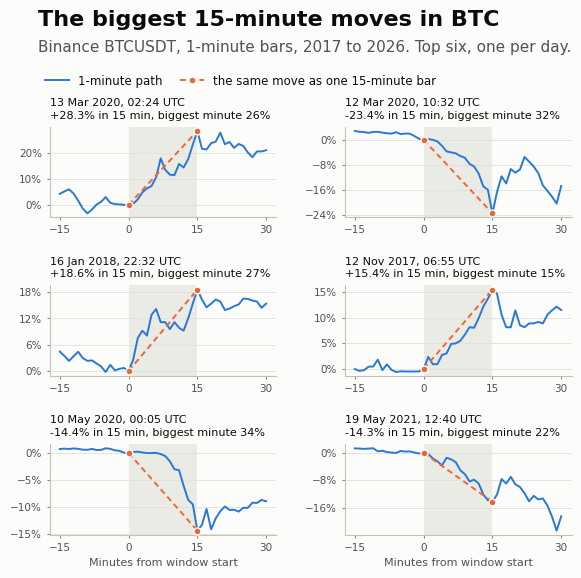

In [3]:
WINDOW, CONTEXT = 15, 15
events = {c: largest_moves(np.log(close[c]), WINDOW, top=50, context_minutes=CONTEXT) for c in COINS}
ev = events[COIN]

fig = jp.event_panel(
    ev.iloc[:6], WINDOW, CONTEXT,
    title=f"The biggest 15-minute moves in {COIN}",
    subtitle=f"Binance {COIN}USDT, 1-minute bars, {close[COIN].index[0]:%Y} to 2026. Top six, one per day.",
)
jp.save(fig, figure_name("01_event_panel"));

In [4]:
table = ev.drop(columns=["path_pct", "end"]).copy()
table["window_return"] = 100 * table["window_return"]
table["largest_minute"] = 100 * table["largest_minute"]
table["largest_minute_share"] = 100 * table["largest_minute_share"]
table.index = table.index.strftime("%Y-%m-%d %H:%M")
table.columns = ["15-min move (%)", "largest 1-min return (%)", "its share of the move (%)", "minutes to half the move"]
print(f"{COIN}: the twelve largest of the top {len(ev)} fifteen-minute moves")
table.head(12).round(1)

BTC: the twelve largest of the top 50 fifteen-minute moves


,15-min move (%),largest 1-min return (%),its share of the move (%),minutes to half the move
start,,,,
2020-03-13 02:24,28.3,7.2,25.6,7
2020-03-12 10:32,-23.4,-7.5,32.1,13
2018-01-16 22:32,18.6,5.0,26.8,5
2017-11-12 06:55,15.4,2.4,15.3,10
2020-05-10 00:05,-14.4,-4.9,33.9,13
2021-05-19 12:40,-14.3,-3.2,22.2,10
2019-06-26 20:29,-14.1,-4.5,31.7,11
2021-12-04 05:12,-14.0,-4.6,33.2,14
2018-01-11 04:40,13.1,3.3,25.2,7


Now the same statistics for all four coins, over the top fifty moves of each.

In [5]:
def summary(e):
    share = 100 * e["largest_minute_share"]
    top = e.iloc[0]
    return {"Largest move (%)": 100 * top["window_return"],
            "On": f"{e.index[0]:%Y-%m-%d %H:%M}",
            "Its biggest minute (% of move)": 100 * top["largest_minute_share"],
            "Biggest minute, median over top 50 (%)": share.median(),
            "Top 50 where one minute carries over half": int((share > 50).sum()),
            "Minutes to cover half the move, median": e["minutes_to_half"].median()}

pd.DataFrame.from_dict({c: summary(e) for c, e in events.items()}, orient="index").round(1)

,Largest move (%),On,Its biggest minute (% of move),"Biggest minute, median over top 50 (%)",Top 50 where one minute carries over half,"Minutes to cover half the move, median"
BTC,28.3,2020-03-13 02:24,25.6,28.4,3,10.0
ETH,24.8,2020-03-13 02:24,31.7,27.8,5,11.0
XRP,-59.5,2025-10-10 21:05,41.7,27.9,4,12.0
SOL,-27.5,2021-05-19 12:40,19.0,31.4,8,11.0


For Bitcoin the biggest minute of the six largest moves carries between 15% and 34% of the move, and it takes five to fourteen minutes to cover half of it. Across the top fifty, one minute carries more than half the move in three cases out of fifty.

The other three coins say the same thing. The median share of the biggest minute is within a few points of 30% for every coin, and the median time to cover half the move is ten to twelve minutes. The thinner books of XRP and SOL do not make the moves more sudden. XRP's largest move is the crash of 10 October 2025, a log return of -59% in fifteen minutes, which is a fall of 45%. Even there the worst single minute carries less than half of it.

On a 15-minute chart each of these is one candle, and to a test that only sees candles, one candle is a jump.

## 2. What the standard jump test sees, bar size by bar size

Log price with stochastic volatility and finite-activity jumps:

$$X_t = X_0 + \int_0^t \mu_s\,ds + \int_0^t \sigma_s\,dW_s + \sum_{k=1}^{N_t} J_k$$

Over one day with $n$ intraday returns $r_i$, realized variance picks up both components, bipower variation only the continuous one:

$$\mathrm{RV} = \sum_{i=1}^{n} r_i^2 \;\longrightarrow\; \int_0^1 \sigma_s^2\,ds + \sum_{k} J_k^2
\qquad
\mathrm{BV} = \frac{\pi}{2}\,\frac{n}{n-1}\sum_{i=2}^{n} |r_i|\,|r_{i-1}| \;\longrightarrow\; \int_0^1 \sigma_s^2\,ds$$

A jump sits in one return only, so the product of adjacent absolute returns kills it in the limit. The relative jump measure is the gap,

$$\mathrm{RJ} = \frac{\mathrm{RV} - \mathrm{BV}}{\mathrm{RV}},$$

and the Barndorff-Nielsen and Shephard test in the ratio form of Huang and Tauchen (2005) is asymptotically standard normal on a day without jumps:

$$z = \frac{\mathrm{RJ}}{\sqrt{\left(\frac{\pi^2}{4} + \pi - 5\right)\frac{1}{n}\,\max\!\left(1, \frac{\mathrm{TQ}}{\mathrm{BV}^2}\right)}}$$

with TQ the tripower quarticity. The limit needs volatility to be roughly constant across *adjacent* returns. A move that unfolds over several minutes but sits inside one bar breaks that assumption, and the whole move is booked to the jump component.

The jump share below is $1 - \sum \mathrm{BV} / \sum \mathrm{RV}$ over all days, so it is not floored at zero. Days with a data gap longer than five minutes are dropped.

In [6]:
INTERVALS = {"1m": 1, "5m": 5, "15m": 15, "30m": 30, "1h": 60}
EMP_LABELS = list(INTERVALS)

grids = {c: to_daily_grid(close[c]) for c in COINS}
empirical = {c: jump_summary(g.to_numpy(), list(INTERVALS.values())) for c, g in grids.items()}
print("Complete days: " + ", ".join(f"{c} {len(g):,}" for c, g in grids.items()))

emp_table = pd.concat(
    {"Jump share of variance (%)": pd.DataFrame({c: 100 * r["jump_share"] for c, r in empirical.items()}, index=EMP_LABELS),
     "Days flagged at 1% (%)": pd.DataFrame({c: 100 * r["days_flagged"] for c, r in empirical.items()}, index=EMP_LABELS)},
    axis=1)
emp_table.round(1).rename_axis("Sampling interval")

Complete days: BTC 3,307, ETH 3,307, XRP 3,068, SOL 2,254


Jump share of variance (%)                  Days flagged at 1% (%)                  
                                         BTC   ETH   XRP  SOL                    BTC   ETH   XRP   SOL
Sampling interval                                                                                     
1m                                       7.4   7.7   2.6  5.6                   34.4  34.0  39.0  36.0
5m                                       6.8   5.9   5.4  5.7                   20.1  20.2  17.0  13.4
15m                                      7.4   7.1   6.3  6.0                   14.5  14.5  11.3   9.1
30m                                     10.3   9.7   9.1  5.8                   12.9  14.1  11.2   8.0
1h                                      15.4  13.5  11.4  7.3                   11.6  11.3   8.3   6.2

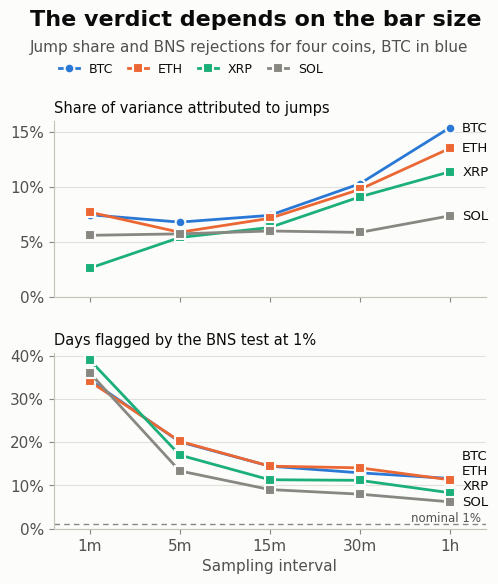

In [7]:
others = iter([jp.ORANGE, jp.AQUA, jp.MUTED])
curves = {c: {"x": range(len(EMP_LABELS)),
              "jump_share": 100 * empirical[c]["jump_share"],
              "days_flagged": 100 * empirical[c]["days_flagged"],
              "color": jp.BLUE if c == COIN else next(others),
              "marker": "o" if c == COIN else "s"}
          for c in [COIN] + [c for c in COINS if c != COIN]}
fig = jp.sampling_curves(
    curves, EMP_LABELS,
    title="The verdict depends on the bar size",
    subtitle=f"Jump share and BNS rejections for four coins, {COIN} in blue",
)
jp.save(fig, figure_name("01_jump_share_by_sampling"));

Three things to read off this chart.

- **The jump share depends on the clock.** For BTC it halves from hourly to 5-minute bars, then ticks back up at 1 minute. ETH does the same. Same days, same prices, different clock. The small uptick at 1 minute is where posts 2 and 3 start.
- **Thinner coins do not have more jumps.** XRP and SOL, the less liquid two, show jump shares no higher than BTC's at any bar size. If anything they are lower, and SOL's barely moves with the clock at all.
- **The test fires everywhere.** At 1-minute sampling it rejects "no jumps" on more than a third of all days for every coin, against a nominal 1%. Part of that is real jumps, part of it is intraday seasonality of volatility, which also violates the locally-constant assumption. That is post 2.

## 3. Which way does the curve bend? A small simulation

Is the fall of the jump share with finer bars what a continuous path does, or what a jump process does? Three simulated worlds on a 5-second grid, sharing the same daily volatility level and intraday pattern at 50% annualised volatility:

- **Bursts, no jumps.** A continuous path where volatility spikes to 10 to 25 times its level about every other day and decays with a 60-second half-life. True jump share: 0%.
- **Poisson jumps.** No bursts; compound Poisson jumps with Gaussian sizes at the same rate, carrying 10% of total variance.
- **Variance gamma.** Brownian motion run on a gamma clock, $X_t = \sigma\, W_{G_t}$ with $G$ a gamma subordinator. Purely discontinuous, infinitely many small jumps, no diffusion component at all. Its true "jump share" is 100%.

As sampling gets finer, bipower variation converges to the integrated variance of the *continuous* part. For the bursts world that is everything, so the jump share falls to zero. For the Poisson world it is 90%, so the share settles near 10%. For variance gamma there is no continuous part, so the share rises towards 100%. The direction of the empirical curve is therefore evidence about which description fits.

One caveat on the third world: plain variance gamma has independent increments, so it cannot cluster activity in time. A stochastic clock is needed for that, which is where post 4 picks up.

In [8]:
DT = 5  # seconds
SIM_INTERVALS = {"5s": 5, "15s": 15, "1m": 60, "5m": 300, "15m": 900, "30m": 1800, "1h": 3600}
SIM_LABELS = list(SIM_INTERVALS)
sim_steps = [s // DT for s in SIM_INTERVALS.values()]

worlds = {
    "Bursts, no jumps": simulate_log_prices("bursts", n_days=250, dt_seconds=DT, seed=0),
    "Poisson jumps": simulate_log_prices("jumps", n_days=250, dt_seconds=DT, seed=0),
    "Variance gamma": simulate_log_prices("vg", n_days=250, dt_seconds=DT, seed=0),
}
sim = {name: jump_summary(lp, sim_steps) for name, lp in worlds.items()}
sim_table = pd.DataFrame({name: 100 * r["jump_share"] for name, r in sim.items()}, index=SIM_LABELS)
sim_table.round(1).rename_axis("Sampling interval")

,"Bursts, no jumps",Poisson jumps,Variance gamma
Sampling interval,,,
5s,0.5,9.0,99.1
15s,0.7,8.7,97.3
1m,2.3,8.2,89.8
5m,4.3,7.5,63.9
15m,5.0,6.7,36.8
30m,4.9,6.6,23.2
1h,5.0,7.5,12.9


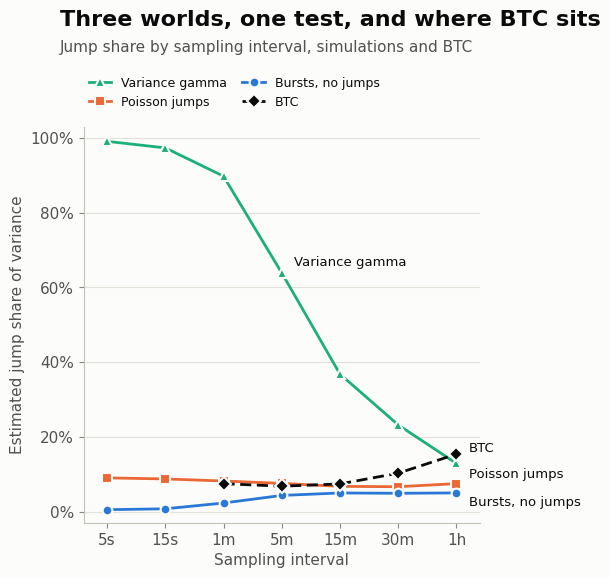

In [9]:
x_sim = list(range(len(SIM_LABELS)))
x_emp = [SIM_LABELS.index(k) for k in EMP_LABELS]
series = [
    {"name": "Variance gamma", "x": x_sim, "y": 100 * sim["Variance gamma"]["jump_share"], "color": jp.AQUA, "marker": "^", "label_at": 3, "dy": 8},
    {"name": "Poisson jumps", "x": x_sim, "y": 100 * sim["Poisson jumps"]["jump_share"], "color": jp.ORANGE, "marker": "s", "dy": 7},
    {"name": "Bursts, no jumps", "x": x_sim, "y": 100 * sim["Bursts, no jumps"]["jump_share"], "color": jp.BLUE, "marker": "o", "dy": -7},
    {"name": COIN, "x": x_emp, "y": 100 * empirical[COIN]["jump_share"], "color": jp.INK, "marker": "D", "ls": (0, (4, 2)), "dy": 4},
]
fig = jp.worlds_plot(
    series, SIM_LABELS,
    title=f"Three worlds, one test, and where {COIN} sits",
    subtitle=f"Jump share by sampling interval, simulations and {COIN}",
)
jp.save(fig, figure_name("01_three_worlds"));

Down to 5 minutes every coin bends the way the continuous worlds do, not the way a pure-jump process does. That rules out "a variance gamma process with nothing else" for all four on this evidence. Between 5 minutes and 1 minute the curves of BTC and ETH tick up, which is the direction a pure-jump component would push them. XRP's keeps falling and SOL's stays flat. Whether that uptick is intraday seasonality, microstructure noise or genuine small jumps is exactly what posts 2 and 3 are for.

## 4. Caveats

- A smooth path at 1 minute does not rule out small jumps at tick level. It rules out one large discontinuity.
- Microstructure noise distorts both RV and BV at the finest frequencies, more so for thinner coins whose price often does not move from one minute to the next. Tick-level work needs noise-robust estimators such as pre-averaging (post 3).
- With 1-minute bars only the right-hand part of the sampling curve is visible. The simulation shows what the left-hand part can look like, under hand-picked parameters.
- The simulation is a sanity check, not a model of any coin: no leverage effect, no microstructure noise, no clustering of activity in the variance gamma world.
- Intraday seasonality of volatility inflates the rejection rate on its own, at every sampling interval (post 2).
- Histories differ in length. SOL starts in August 2020 and XRP in May 2018, so their top moves are drawn from a shorter, and for SOL more recent, record.

## 5. Takeaways

1. The largest 15-minute moves are multi-minute slides, not discontinuities, for all four coins. The biggest single minute carries about 30% of the move at the median.
2. Less liquid coins do not move more suddenly. XRP and SOL show the same shape of move and a lower bar-based jump share than BTC.
3. A bar-based jump test cannot see the difference. Its jump share and its rejection rate are properties of the bar size as much as of the price.
4. From hourly to 5-minute bars the empirical jump share falls or stays flat, which is the signature of a continuous path with bursts, not of a pure-jump process.
5. On equities and FX tick data, Christensen, Oomen and Podolskij found that jumps account for about 1% of total price variation, an order of magnitude below estimates from lower-frequency data. These coins at 1 minute are still well above that, and posts 2 and 3 take the next two bites out of it.

## Equation images for the post

LinkedIn does not render LaTeX, so the key equations are exported as images.

In [10]:
jp.render_equation(r"\mathrm{RV}=\sum_{i=1}^{n} r_i^2\ \rightarrow\ \int_0^1\sigma_s^2\,ds+\sum_k J_k^2",
                   "01_eq_rv", "Realized variance captures diffusion and jumps")
jp.render_equation(r"\mathrm{BV}=\dfrac{\pi}{2}\sum_{i=2}^{n}|r_i|\,|r_{i\!-\!1}|\ \rightarrow\ \int_0^1\sigma_s^2\,ds",
                   "01_eq_bv", "Bipower variation captures diffusion only")
jp.render_equation(r"\mathrm{RJ}=\dfrac{\mathrm{RV}-\mathrm{BV}}{\mathrm{RV}}",
                   "01_eq_rj", "Relative jump measure: the share of variance attributed to jumps")
jp.render_equation(r"X_t=\sigma\,W_{G_t},\qquad G_t\sim\Gamma(t/\nu,\ \nu)",
                   "01_eq_vg", "Variance gamma: Brownian motion on a gamma clock, no diffusion part");

## References

- Christensen, K., Oomen, R. C. A. and Podolskij, M. (2014). Fact or friction: Jumps at ultra high frequency. *Journal of Financial Economics*, 114(3), 576-599. [arXiv:2602.10925](https://arxiv.org/abs/2602.10925) · [doi:10.1016/j.jfineco.2014.07.007](https://doi.org/10.1016/j.jfineco.2014.07.007)
- Barndorff-Nielsen, O. E. and Shephard, N. (2004). Power and bipower variation with stochastic volatility and jumps. *Journal of Financial Econometrics*, 2(1), 1-37. [doi:10.1093/jjfinec/nbh001](https://doi.org/10.1093/jjfinec/nbh001)
- Huang, X. and Tauchen, G. (2005). The relative contribution of jumps to total price variance. *Journal of Financial Econometrics*, 3(4), 456-499. [RePEc](https://ideas.repec.org/a/oup/jfinec/v3y2005i4p456-499.html)

---

*Code, data loaders and figures: [github.com/PascalLemieux/jumps](https://github.com/PascalLemieux/jumps). Comments and corrections welcome on [LinkedIn](https://linkedin.com/in/pascal-lemieux).*